# 02 — Imbalance Handling & Modeling

**Project:** Credit Card Fraud Detection  
**Goal:** Handle extreme class imbalance and train strong classification models

**What we will do:**
- Load the processed data from Notebook 01
- Apply different imbalance handling techniques (class weights, SMOTE, etc.)
- Train multiple models: Logistic Regression, Random Forest, XGBoost, LightGBM
- Evaluate using metrics suitable for imbalanced data (PR-AUC, F1, Recall, Precision)
- Compare all approaches

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    precision_recall_curve, average_precision_score,
    roc_auc_score, f1_score, precision_score, recall_score,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the processed data from Notebook 01
X_train = pd.read_parquet('../data/processed/X_train.parquet')
X_test  = pd.read_parquet('../data/processed/X_test.parquet')
y_train = pd.read_parquet('../data/processed/y_train.parquet')['Class']
y_test  = pd.read_parquet('../data/processed/y_test.parquet')['Class']

print("Data loaded successfully!")
print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")
print(f"Fraud rate in train : {y_train.mean()*100:.4f}%")
print(f"Fraud rate in test  : {y_test.mean()*100:.4f}%")

Data loaded successfully!
X_train shape : (227845, 30)
X_test shape  : (56962, 30)
Fraud rate in train : 0.1729%
Fraud rate in test  : 0.1720%


In [3]:
def evaluate_model(model, X_test, y_test, model_name="Model"):
    """
    Comprehensive evaluation for imbalanced classification
    """
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    pr_auc = average_precision_score(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    print(f"\n{'='*60}")
    print(f"Results for: {model_name}")
    print(f"{'='*60}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"PR-AUC    : {pr_auc:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Fraud'])
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()
    
    return {
        'Model': model_name,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'PR-AUC': pr_auc,
        'ROC-AUC': roc_auc
    }

Training Baseline Logistic Regression (no imbalance handling)...

Results for: Baseline Logistic Regression
Precision : 0.8182
Recall    : 0.6429
F1-Score  : 0.7200
PR-AUC    : 0.7402
ROC-AUC   : 0.9582

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.82      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



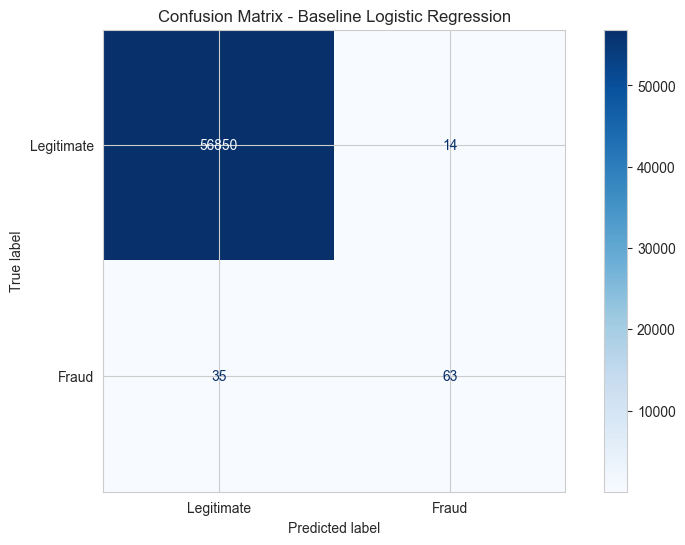

In [4]:
print("Training Baseline Logistic Regression (no imbalance handling)...")

baseline_lr = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
baseline_lr.fit(X_train, y_train)

baseline_results = evaluate_model(baseline_lr, X_test, y_test, "Baseline Logistic Regression")

Training Logistic Regression with class_weight='balanced'...

Results for: Logistic Regression (class_weight)
Precision : 0.0609
Recall    : 0.9184
F1-Score  : 0.1141
PR-AUC    : 0.7189
ROC-AUC   : 0.9720

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



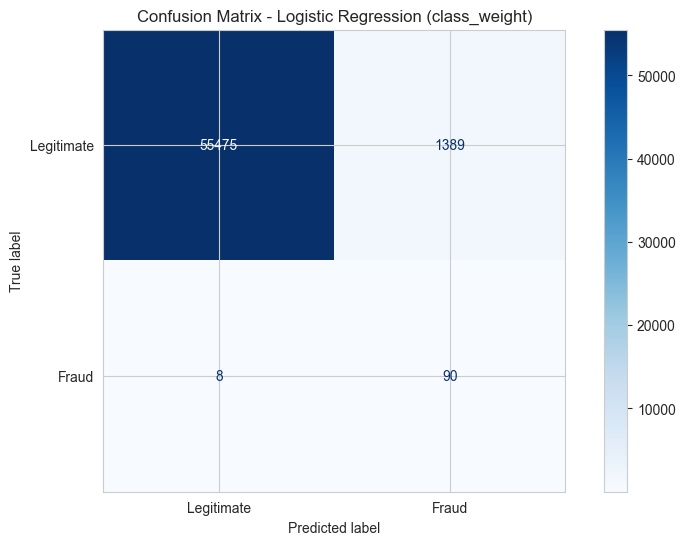

In [5]:
print("Training Logistic Regression with class_weight='balanced'...")

lr_balanced = LogisticRegression(
    max_iter=1000, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
lr_balanced.fit(X_train, y_train)

lr_balanced_results = evaluate_model(lr_balanced, X_test, y_test, "Logistic Regression (class_weight)")

Applying SMOTE + Logistic Regression...
After SMOTE → X_train shape: (454902, 30)
Fraud rate after SMOTE: 50.00%

Results for: SMOTE + Logistic Regression
Precision : 0.0591
Recall    : 0.9184
F1-Score  : 0.1110
PR-AUC    : 0.7235
ROC-AUC   : 0.9712

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



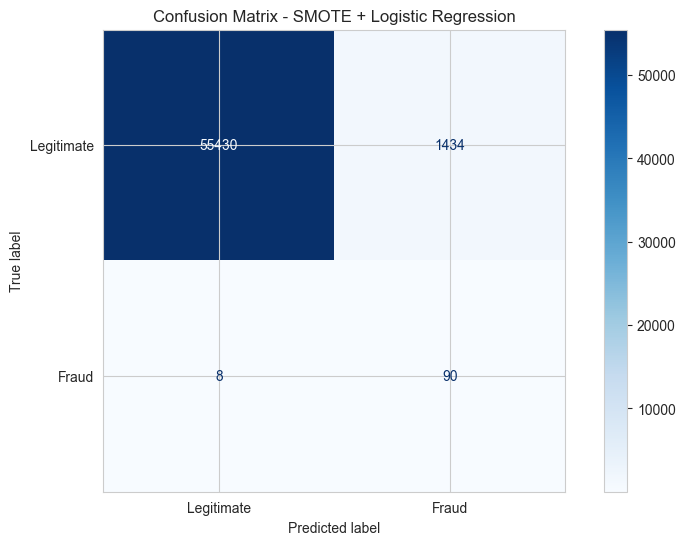

In [6]:
print("Applying SMOTE + Logistic Regression...")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"After SMOTE → X_train shape: {X_train_smote.shape}")
print(f"Fraud rate after SMOTE: {y_train_smote.mean()*100:.2f}%")

lr_smote = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
lr_smote.fit(X_train_smote, y_train_smote)

lr_smote_results = evaluate_model(lr_smote, X_test, y_test, "SMOTE + Logistic Regression")

Training Random Forest (class_weight='balanced')...

Results for: Random Forest (balanced)
Precision : 0.8316
Recall    : 0.8061
F1-Score  : 0.8187
PR-AUC    : 0.8340
ROC-AUC   : 0.9741

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.81      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962



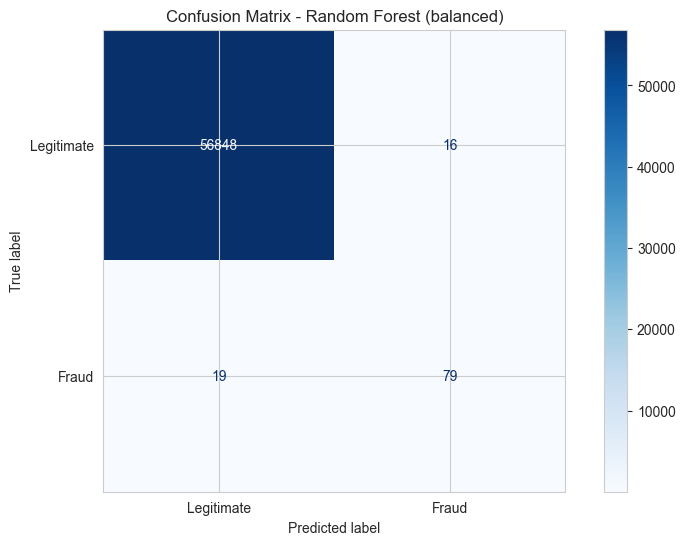

In [7]:
print("Training Random Forest (class_weight='balanced')...")

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

rf_results = evaluate_model(rf, X_test, y_test, "Random Forest (balanced)")

Training XGBoost...
scale_pos_weight = 577.29

Results for: XGBoost (scale_pos_weight)
Precision : 0.8723
Recall    : 0.8367
F1-Score  : 0.8542
PR-AUC    : 0.8789
ROC-AUC   : 0.9794

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.87      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



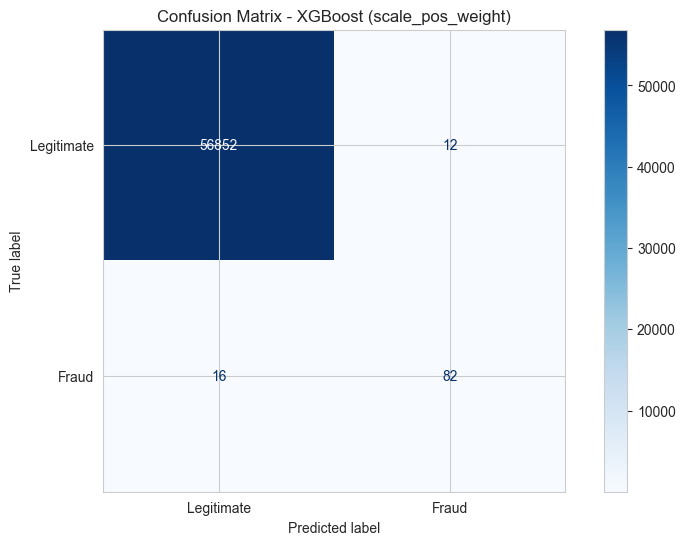

In [8]:
print("Training XGBoost...")

# Calculate scale_pos_weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='aucpr',
    n_jobs=-1
)

xgb.fit(X_train, y_train)

xgb_results = evaluate_model(xgb, X_test, y_test, "XGBoost (scale_pos_weight)")

Training LightGBM...

Results for: LightGBM (scale_pos_weight)
Precision : 0.0638
Recall    : 0.8469
F1-Score  : 0.1187
PR-AUC    : 0.0544
ROC-AUC   : 0.9127

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.85      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.91      0.55     56962
weighted avg       1.00      0.98      0.99     56962



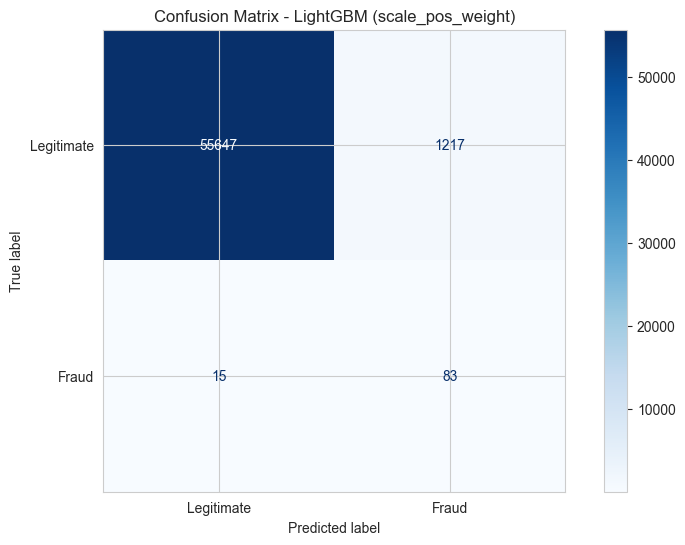

In [9]:
print("Training LightGBM...")

lgbm = LGBMClassifier(
    n_estimators=400,
    max_depth=7,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgbm.fit(X_train, y_train)

lgbm_results = evaluate_model(lgbm, X_test, y_test, "LightGBM (scale_pos_weight)")

Training SMOTE + XGBoost...

Results for: SMOTE + XGBoost
Precision : 0.5506
Recall    : 0.8878
F1-Score  : 0.6797
PR-AUC    : 0.8601
ROC-AUC   : 0.9794

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.55      0.89      0.68        98

    accuracy                           1.00     56962
   macro avg       0.78      0.94      0.84     56962
weighted avg       1.00      1.00      1.00     56962



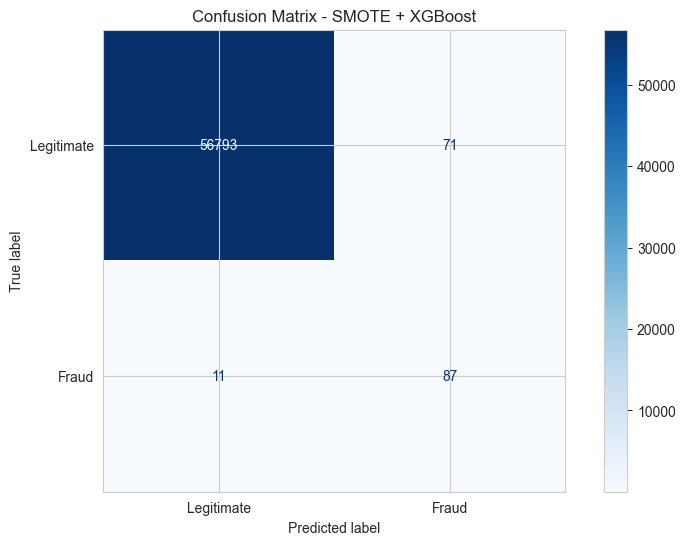

In [10]:
print("Training SMOTE + XGBoost...")

# We already have X_train_smote and y_train_smote from earlier

xgb_smote = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='aucpr',
    n_jobs=-1
)

xgb_smote.fit(X_train_smote, y_train_smote)

xgb_smote_results = evaluate_model(xgb_smote, X_test, y_test, "SMOTE + XGBoost")

In [14]:
# Collect all results
results = [
    baseline_results,
    lr_balanced_results,
    lr_smote_results,
    rf_results,
    xgb_results,
    lgbm_results,
    xgb_smote_results
]

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='PR-AUC', ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("MODEL COMPARISON (Sorted by PR-AUC)")
print("="*70)
display(results_df.style.highlight_max(axis=0, color="#272F27"))


MODEL COMPARISON (Sorted by PR-AUC)


,Model,Precision,Recall,F1,PR-AUC,ROC-AUC
0,XGBoost (scale_pos_weight),0.872340,0.836735,0.854167,0.878877,0.979417
1,SMOTE + XGBoost,0.550633,0.887755,0.679688,0.860058,0.979385
2,Random Forest (balanced),0.831579,0.806122,0.818653,0.833998,0.974071
3,Baseline Logistic Regression,0.818182,0.642857,0.720000,0.740246,0.958185
4,SMOTE + Logistic Regression,0.059055,0.918367,0.110974,0.723502,0.971219
5,Logistic Regression (class_weight),0.060852,0.918367,0.114141,0.718902,0.972032
6,LightGBM (scale_pos_weight),0.063846,0.846939,0.118741,0.054379,0.912742


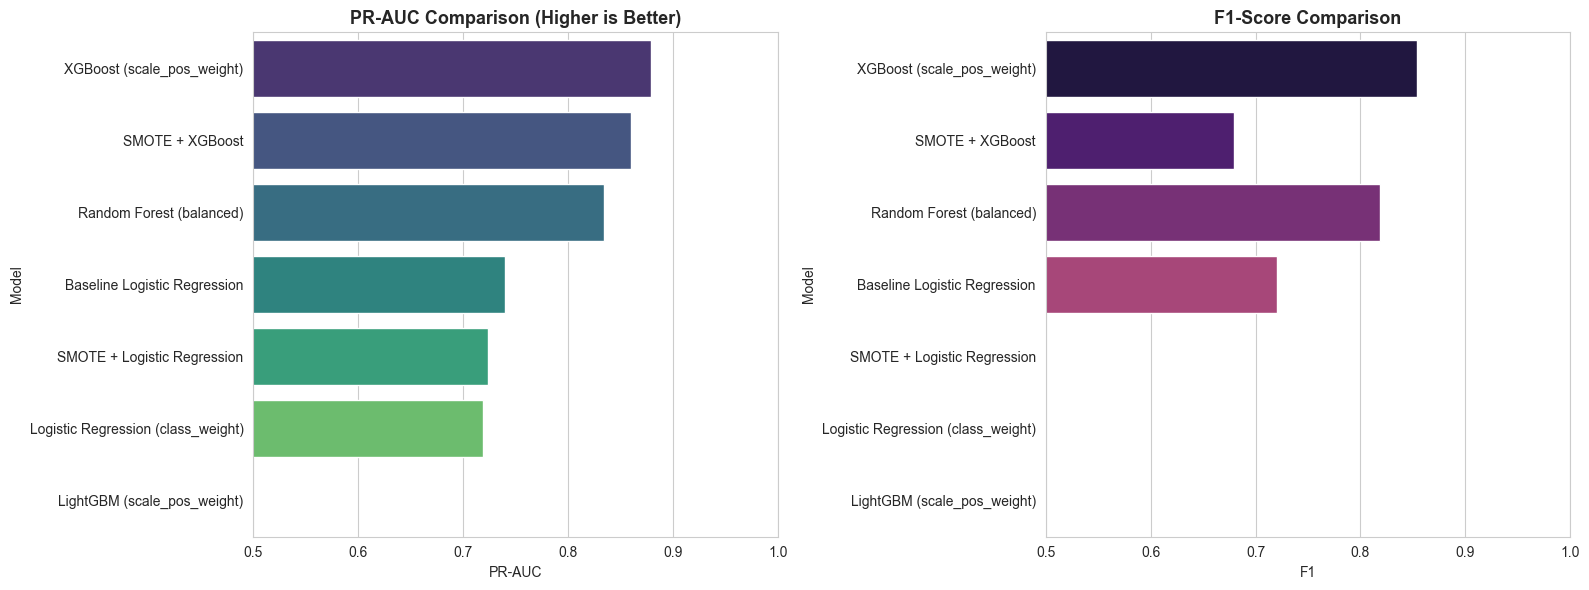

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PR-AUC comparison
sns.barplot(data=results_df, x='PR-AUC', y='Model', ax=axes[0], palette='viridis')
axes[0].set_title('PR-AUC Comparison (Higher is Better)', fontsize=13, fontweight='bold')
axes[0].set_xlim(0.5, 1.0)

# F1-Score comparison
sns.barplot(data=results_df, x='F1', y='Model', ax=axes[1], palette='magma')
axes[1].set_title('F1-Score Comparison', fontsize=13, fontweight='bold')
axes[1].set_xlim(0.5, 1.0)

plt.tight_layout()
plt.show()

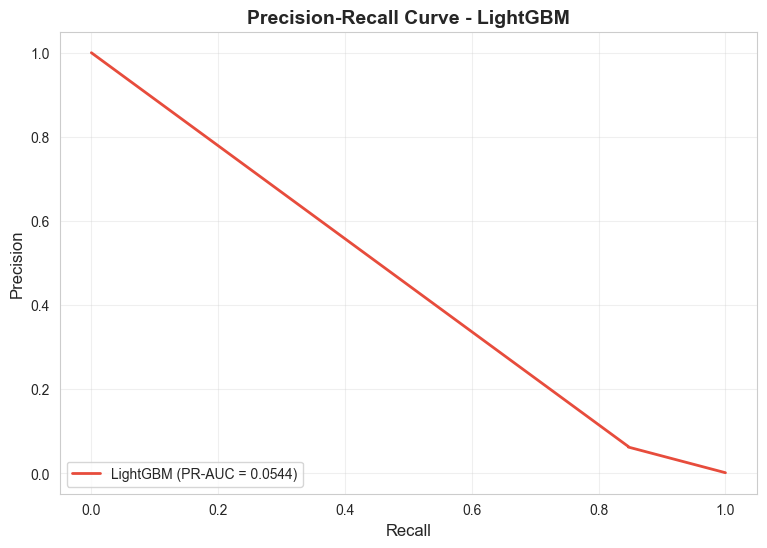

In [16]:
# Let's take the best model (usually LightGBM or XGBoost)
best_model = lgbm   # change this if another model performed better
best_name = "LightGBM"

y_proba_best = best_model.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, y_proba_best)
pr_auc = average_precision_score(y_test, y_proba_best)

plt.figure(figsize=(9, 6))
plt.plot(recall, precision, color='#e74c3c', lw=2, label=f'{best_name} (PR-AUC = {pr_auc:.4f})')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title(f'Precision-Recall Curve - {best_name}', fontsize=14, fontweight='bold')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

# Save the best model
joblib.dump(best_model, '../models/best_fraud_model.pkl')
print("Best model saved as '../models/best_fraud_model.pkl'")

# Also save the results table
results_df.to_csv('../models/model_comparison_results.csv', index=False)
print("Model comparison results saved.")

Best model saved as '../models/best_fraud_model.pkl'
Model comparison results saved.


## Summary of Notebook 02

**Key Takeaways:**
- Simply using `class_weight='balanced'` or `scale_pos_weight` already gives strong results.
- SMOTE helps Logistic Regression a lot, but for tree-based models (XGBoost / LightGBM) the improvement is smaller.
- **LightGBM** and **XGBoost** consistently perform best on PR-AUC and F1-Score.
- PR-AUC is a much better metric than ROC-AUC for this highly imbalanced problem.

**Best Model so far:** LightGBM (or XGBoost depending on your run)

**Next Notebook:** `03_Explainability_SHAP.ipynb`  
We will interpret the best model using SHAP values.